# Imports

In [125]:
from pathlib import Path
import os

# Set the project root
PROJECT_ROOT = Path(r"C:\Users\magnu\OneDrive\Dokumenter\IND320\magloevIND320")

# Set notebook working directory to project root
os.chdir(PROJECT_ROOT)

# Define directories
DATA_DIR = PROJECT_ROOT / "data"
WEATHER_DIR = DATA_DIR / "weather"
FORECAST_WEATHER_DIR = DATA_DIR / "forecast_weather"

In [69]:
import sys
import requests
import pandas as pd
from io import StringIO
from src.data_loader import load_reservoir_data
from src.mongo_loader import load_mongo_data
from src.weather_loader import download_weather
from river import linear_model, preprocessing, optim, metrics
import plotly.graph_objects as go
import json
import openmeteo_requests
import requests_cache
from retry_requests import retry
import numpy as np
import plotly.express as px
from ipywidgets import interact
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Get exchange rates

In [3]:
def get_exchange_rates(start_date, end_date):
    url = "https://data.norges-bank.no/api/data/EXR/B.EUR+USD.NOK.SP"

    params = {
        "startPeriod": start_date,
        "endPeriod": end_date,
        "format": "csv"
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    df = pd.read_csv(StringIO(response.text), sep=";")

    #Extracting relevant columns

    df = df[["TIME_PERIOD", "BASE_CUR", "OBS_VALUE"]].copy()

    df.columns = ["date", "currency", "exchange_rate"]

    df["date"] = pd.to_datetime(df["date"])
    df["exchange_rate"] = pd.to_numeric(df["exchange_rate"])

    return df

In [4]:
exchange_rates = get_exchange_rates("2026-01-01", "2026-01-31")

display(exchange_rates.head())

,date,currency,exchange_rate
0,2026-01-02,USD,10.0661
1,2026-01-05,USD,10.0990
2,2026-01-06,USD,10.0184
3,2026-01-07,USD,10.0638
4,2026-01-08,USD,10.1015


# Checking timezones


In [5]:
df = load_reservoir_data()
print("NVE:")
print(df["date"].dtype)
print(df["date"].head())

print("Norges Bank:")
print(exchange_rates["date"].dtype)
print(exchange_rates["date"].head())

2026-11-24 15:33:37.991 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-24 15:33:37.992 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


NVE:
datetime64[us]
14903   1995-01-08
9951    1995-01-08
7718    1995-01-08
11268   1995-01-08
7118    1995-01-08
Name: date, dtype: datetime64[us]
Norges Bank:
datetime64[us]
0   2026-01-02
1   2026-01-05
2   2026-01-06
3   2026-01-07
4   2026-01-08
Name: date, dtype: datetime64[us]


In [6]:
weather_df = download_weather(
    "NO 3",
    "2024-01-01",
    "2024-12-31"
)

#Adding back the UTC timezone to the ENTSOE data.
entsoe_df = load_mongo_data()
entsoe_df["timestamp"] = pd.to_datetime(
    entsoe_df["timestamp"],
    utc=True
)

Loading saved batch 0
Loading saved batch 100
Loading saved batch 200
Loading saved batch 300
Loading saved batch 400
Loading saved batch 500
Loading saved batch 600
Loading saved batch 700
Loading saved batch 800
Loading saved batch 900


2026-11-24 15:33:42.598 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-24 15:33:42.599 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [7]:
print("Open-meteo:")
print(weather_df["date"].dtype)
print(weather_df["date"].head())

print("ENTSO-E:")
print(entsoe_df["timestamp"].dtype)
print(entsoe_df["timestamp"].head())

Open-meteo:
datetime64[us, UTC]
0   2024-01-01 00:00:00+00:00
1   2024-01-01 01:00:00+00:00
2   2024-01-01 02:00:00+00:00
3   2024-01-01 03:00:00+00:00
4   2024-01-01 04:00:00+00:00
Name: date, dtype: datetime64[us, UTC]
ENTSO-E:
datetime64[us, UTC]
0   2024-10-09 02:00:00+00:00
1   2024-10-10 07:00:00+00:00
2   2024-10-10 08:00:00+00:00
3   2024-10-10 09:00:00+00:00
4   2024-10-10 10:00:00+00:00
Name: timestamp, dtype: datetime64[us, UTC]


# Preparation for ML

# Preparing NVE time series
Will be looking at the EL3 region

In [8]:
df_no3 = (
    df[
        (df["area_type"] == "EL") &
        (df["area_id"] == 3)
    ]
    .sort_values("date")
    .copy()
)

display(df_no3[["date", "fill_level"]].head())
display(df_no3[["date", "fill_level"]].tail())

,date,fill_level
4415,1995-01-08,0.602376
4282,1995-01-15,0.569943
3985,1995-01-22,0.542203
4013,1995-01-29,0.508148
4713,1995-02-05,0.473883


,date,fill_level
8120,2026-10-18,0.724940
8134,2026-10-25,0.717647
8133,2026-11-01,0.720149
8312,2026-11-08,0.718705
8314,2026-11-15,0.697237


# Create lagged variables

In [9]:
df_no3 = df_no3.sort_values("date").copy()

df_no3["lag_1"] = df_no3["fill_level"].shift(1)
df_no3["lag_2"] = df_no3["fill_level"].shift(2)
df_no3["lag_4"] = df_no3["fill_level"].shift(4)
df_no3["lag_52"] = df_no3["fill_level"].shift(52)

display(
    df_no3[
        ["date", "fill_level", "lag_1", "lag_2", "lag_4", "lag_52"]
    ].tail(10)
)

,date,fill_level,lag_1,lag_2,lag_4,lag_52
7642,2026-09-13,0.652494,0.632579,0.627002,0.629866,0.891090
7647,2026-09-20,0.680705,0.652494,0.632579,0.637280,0.893444
8112,2026-09-27,0.715288,0.680705,0.652494,0.627002,0.899940
8117,2026-10-04,0.718754,0.715288,0.680705,0.632579,0.893539
8123,2026-10-11,0.725240,0.718754,0.715288,0.652494,0.926998
8120,2026-10-18,0.724940,0.725240,0.718754,0.680705,0.937354
8134,2026-10-25,0.717647,0.724940,0.725240,0.715288,0.920749
8133,2026-11-01,0.720149,0.717647,0.724940,0.718754,0.895342
8312,2026-11-08,0.718705,0.720149,0.717647,0.725240,0.888638
8314,2026-11-15,0.697237,0.718705,0.720149,0.724940,0.883262


Decided to add lag_52 aswell, as a candidate seasonal feature since the fill_level should follow an annual cycle.The first 52 observations were removed because the lagged features require up to 52 weeks of historical data. Rather than backfilling missing values, which could introduce future information into earlier observations, these rows were dropped. Since the dataset contains approximately 30 years of weekly observations, removing the first year represents only a small reduction in the available training data.

In [10]:
lag_columns = ["lag_1", "lag_2", "lag_4", "lag_52"]

df_model = df_no3.dropna(
    subset=["fill_level"] + lag_columns
).copy()

print("Observations available:", len(df_model))

display(df_model[["date", "fill_level"] + lag_columns].head())

Observations available: 1611


,date,fill_level,lag_1,lag_2,lag_4,lag_52
4011,1996-01-07,0.670686,0.714104,0.753256,0.817361,0.602376
4591,1996-01-14,0.630355,0.670686,0.714104,0.791204,0.569943
4027,1996-01-21,0.590421,0.630355,0.670686,0.753256,0.542203
4000,1996-01-28,0.545880,0.590421,0.630355,0.714104,0.508148
823,1996-02-04,0.502266,0.545880,0.590421,0.670686,0.473883


# Set up River Model

In [11]:
model = (
    preprocessing.StandardScaler()
    | linear_model.LinearRegression(
        optimizer=optim.SGD(0.01)
    )
)

# Train-test split
Separate it in chronological order, if not the model would learn from future periods.

In [12]:
features = ["lag_1", "lag_2", "lag_4", "lag_52"]

split = int(len(df_model) * 0.8)

train = df_model.iloc[:split]
test = df_model.iloc[split:]

print("Training:", train["date"].min(), "to", train["date"].max())
print("Testing:", test["date"].min(), "to", test["date"].max())

Training: 1996-01-07 00:00:00 to 2020-09-06 00:00:00
Testing: 2020-09-13 00:00:00 to 2026-11-15 00:00:00


# Training the model

In [13]:
for _, row in train.iterrows():
    x = row[features].to_dict()
    y = float(row["fill_level"])

    model.learn_one(x, y)

# Evaluate

In [14]:
mae = metrics.MAE()
predictions = []

for _, row in test.iterrows():
    x = row[features].to_dict()
    y = float(row["fill_level"])

    y_pred = model.predict_one(x)

    predictions.append(y_pred)
    mae.update(y, y_pred)

print(mae)

MAE: 0.028458


# Visualization

In [15]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=test["date"],
    y=test["fill_level"],
    name="Actual"
))

fig.add_trace(go.Scatter(
    x=test["date"],
    y=predictions,
    name="Predicted"
))

fig.update_layout(
    title="River: Actual vs Predicted Reservoir Filling",
    xaxis_title="Date",
    yaxis_title="Filling level"
)

fig.show()

In [16]:
from sklearn.metrics import mean_absolute_error

baseline_mae = mean_absolute_error(
    test["fill_level"],
    test["lag_1"]
)

river_mae = mean_absolute_error(
    test["fill_level"],
    predictions
)

print(f"Baseline MAE: {baseline_mae:.4f}")
print(f"River MAE:    {river_mae:.4f}")

Baseline MAE: 0.0265
River MAE:    0.0285


# Recursive forecasting function

In [17]:
def recursive_forecast(model, history, lags, horizon=12):

    history = list(history)
    predictions = []

    for step in range(horizon):

        # Construct features from the selected lags
        x = {
            f"lag_{lag}": history[-lag]
            for lag in lags
        }

        # Predict the next week's filling level
        prediction = model.predict_one(x)

        predictions.append(prediction)

        # Add prediction to history for subsequent forecasts
        history.append(prediction)

    return predictions

# Test on historical data first

In [18]:
horizon = 12
lags = [1, 2, 4, 52]

# Actual filling levels available before the test period
history = train["fill_level"].tolist()

forecast = recursive_forecast(
    model,
    history,
    lags,
    horizon=horizon
)

actual = test["fill_level"].iloc[:horizon].to_numpy()
dates = test["date"].iloc[:horizon]

print("12-week forecast MAE:", mean_absolute_error(actual, forecast))

12-week forecast MAE: 0.09133979897137973


# Check against baseline

In [19]:
baseline = [history[-1]] * horizon

print("River MAE:", mean_absolute_error(actual, forecast))
print("Baseline MAE:", mean_absolute_error(actual, baseline))

River MAE: 0.09133979897137973
Baseline MAE: 0.017846696666666644


In [20]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=dates,
    y=actual,
    mode="lines+markers",
    name="Actual"
))

fig.add_trace(go.Scatter(
    x=dates,
    y=forecast,
    mode="lines+markers",
    name="River forecast",
    line=dict(color="orange")
))

fig.add_trace(go.Scatter(
    x=dates,
    y=baseline,
    mode="lines",
    name="Persistence baseline",
    line=dict(dash="dash")
))

fig.update_layout(
    title="12-week Recursive Reservoir Filling Forecast",
    xaxis_title="Date",
    yaxis_title="Filling level",
    yaxis_range=[0, 1]
)

fig.show()

# Chronological backtesting

In [21]:
horizon = 12
lags = [1, 2, 4, 52]

river_errors = []
baseline_errors = []
all_values = df_model["fill_level"].to_numpy()
test_start = len(train)

for start in range(test_start, len(df_model) - horizon + 1, horizon):

    history = all_values[:start]
    actual = all_values[start:start + horizon]

    river_forecast = recursive_forecast(
        model,
        history,
        lags,
        horizon=horizon
    )

    baseline_forecast = [history[-1]] * horizon

    river_errors.append(
        mean_absolute_error(actual, river_forecast)
    )

    baseline_errors.append(
        mean_absolute_error(actual, baseline_forecast)
    )

print("Average River MAE:", sum(river_errors) / len(river_errors))
print("Average baseline MAE:", sum(baseline_errors) / len(baseline_errors))

Average River MAE: 0.11701155886398316
Average baseline MAE: 0.14387118705128205


From what we see so far, the River performs better than the baseline when we introduced chronological backtesting. This means that, probably, river is better at predicting periods with larger changes, while baseline generally predicts better when the fill_level is stable. We will now experiment with different lags to see if lag_52 actually improves the model, or if we only need the recent history. 

In [22]:
def train_river(train_data, features, learning_rate=0.01):

    model = (
        preprocessing.StandardScaler()
        | linear_model.LinearRegression(
            optimizer=optim.SGD(learning_rate)
        )
    )

    for _, row in train_data.iterrows():
        x = row[features].to_dict()
        y = float(row["fill_level"])

        model.learn_one(x, y)

    return model

In [23]:
lags_a = [1, 2, 4]
lags_b = [1, 2, 4, 52]

model_a = train_river(
    train,
    features=[f"lag_{lag}" for lag in lags_a]
)

model_b = train_river(
    train,
    features=[f"lag_{lag}" for lag in lags_b]
)

In [24]:
horizon = 12
all_values = df_model["fill_level"].to_numpy()
test_start = len(train)

errors_a = []
errors_b = []

for start in range(test_start, len(df_model) - horizon + 1, horizon):

    history = all_values[:start]
    actual = all_values[start:start + horizon]

    forecast_a = recursive_forecast(
        model_a, history, lags=lags_a, horizon=horizon
    )

    forecast_b = recursive_forecast(
        model_b, history, lags=lags_b, horizon=horizon
    )

    errors_a.append(mean_absolute_error(actual, forecast_a))
    errors_b.append(mean_absolute_error(actual, forecast_b))

print(f"Without seasonal lag: {sum(errors_a)/len(errors_a):.4f}")
print(f"With seasonal lag:    {sum(errors_b)/len(errors_b):.4f}")

Without seasonal lag: 0.1259
With seasonal lag:    0.1170


Suggests that including seasonal lag improves the model. Our next step is to test different history lengths to see if it improves the model.

In [25]:
lags = [1, 2, 4, 52]
features = [f"lag_{lag}" for lag in lags]

history_lengths = [5, 10, 20, "All"]
results = {}

for years in history_lengths:

    if years == "All":
        train_subset = train
    else:
        # Approximate number of weekly observations
        n_weeks = years * 52
        train_subset = train.iloc[-n_weeks:]

    # Train a new model for each history length
    current_model = train_river(
        train_subset,
        features=features
    )

    errors = []

    for start in range(test_start, len(df_model) - horizon + 1, horizon):

        history = all_values[:start]
        actual = all_values[start:start + horizon]

        forecast = recursive_forecast(
            current_model,
            history,
            lags=lags,
            horizon=horizon
        )

        errors.append(mean_absolute_error(actual, forecast))

    results[years] = sum(errors) / len(errors)

for years, mae in results.items():
    print(f"{years} years: MAE = {mae:.4f}")

5 years: MAE = 0.1588
10 years: MAE = 0.1145
20 years: MAE = 0.1187
All years: MAE = 0.1170


Accordint to this, a history length of 10 years is preferred, which beats both 20 years and all years by a small margin. We see that 5 years has MAE = 0.159, which tells us that it may not provide enough data. Considering that 10 years is actually better than 20 years and all years, it looks like older observations doesnt really help the model. 

Our next step would be to compare forecasting horizons. 

In [26]:
lags = [1, 2, 4, 52]
features = [f"lag_{lag}" for lag in lags]

# Train on the most recent 10 years before the test period
model_10y = train_river(
    train.iloc[-10 * 52:],
    features=features
)

horizons = [4, 8, 12, 16]

for h in horizons:
    river_errors = []
    baseline_errors = []

    for start in range(test_start, len(df_model) - h + 1, h):

        history = all_values[:start]
        actual = all_values[start:start + h]

        forecast = recursive_forecast(
            model_10y, history, lags=lags, horizon=h
        )

        baseline = [history[-1]] * h

        river_errors.append(mean_absolute_error(actual, forecast))
        baseline_errors.append(mean_absolute_error(actual, baseline))

    print(
        f"{h:2d} weeks | "
        f"River MAE: {sum(river_errors)/len(river_errors):.4f} | "
        f"Baseline MAE: {sum(baseline_errors)/len(baseline_errors):.4f}"
    )

 4 weeks | River MAE: 0.0647 | Baseline MAE: 0.0620
 8 weeks | River MAE: 0.0968 | Baseline MAE: 0.1024
12 weeks | River MAE: 0.1145 | Baseline MAE: 0.1439
16 weeks | River MAE: 0.1290 | Baseline MAE: 0.1741


We see that the error increasing as length of prediction increases, which is to be expected. We also see that the baseline becomes worse and worse compared to River, which is a good sign that River can make somewhat reasonable predictions.

In [27]:
from pathlib import Path

weather_dir = Path("data/weather")

for file in weather_dir.glob("*.csv"):
    print(file.name, round(file.stat().st_size / 1_000_000, 2), "MB")

NO 3_2024-01-01_2024-12-31_average.csv 0.45 MB


# Connecting with Open-Meteo
My next goal is to introduce open-meteo data, staarting with weekly precipitation and temperature. These factors should increase the accuracy of the model.
I will do this by first using only 100 locations instead of 1000, and fetch daily, not hourly observations from open-meteo. This should make the downloading quicker, and we could of course expand the locations later again if that is feasible.

In [28]:
coordinates_path = PROJECT_ROOT / "data" / "weather" / "zone_coordinates.json"

with open(coordinates_path, "r", encoding="utf-8") as f:
    zone_coordinates = json.load(f)

no3_coordinates = zone_coordinates["NO 3"][:100]

print(f"Selected {len(no3_coordinates)} locations")
print(no3_coordinates[:5])

Selected 100 locations
[[9.242168144376933, 63.747286169983724], [10.634300385849494, 63.02200095168361], [9.658707025216366, 63.104202632143185], [6.939771425111094, 62.1563555293372], [7.497796087593908, 62.438419936067476]]


# Testing for 1 coordinate

In [29]:
# Coordinates are stored as [longitude, latitude]
lon, lat = no3_coordinates[0]

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": lat,
    "longitude": lon,
    "start_date": "2024-01-01",
    "end_date": "2024-12-31",
    "daily": "temperature_2m_mean,precipitation_sum",
    "timezone": "Europe/Oslo"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()

df_weather_test = pd.DataFrame(data["daily"])
df_weather_test["time"] = pd.to_datetime(df_weather_test["time"])

print(df_weather_test.head())
print(df_weather_test.shape)

        time  temperature_2m_mean  precipitation_sum
0 2024-01-01                 -0.9                0.0
1 2024-01-02                 -3.1                0.0
2 2024-01-03                 -4.7                0.0
3 2024-01-04                 -3.6                0.1
4 2024-01-05                  0.5                1.6
(366, 3)


# Function for downloading weather

In [30]:
PROJECT_ROOT = Path.cwd()
FORECAST_WEATHER_DIR = PROJECT_ROOT / "data" / "forecast_weather"

# Initialize Open-Meteo API client
cache_session = requests_cache.CachedSession(
    str(PROJECT_ROOT / ".cache"),
    expire_after=3600
)

retry_session = retry(
    cache_session,
    retries=5,
    backoff_factor=0.2
)

openmeteo = openmeteo_requests.Client(session=retry_session)

print(f"Selected coordinates: {len(no3_coordinates)}")
print(f"Forecast weather directory: {FORECAST_WEATHER_DIR}")

Selected coordinates: 100
Forecast weather directory: C:\Users\magnu\OneDrive\Dokumenter\IND320\magloevIND320\data\forecast_weather


In [31]:
def download_forecast_weather(region, start_date, end_date):
    """
    Download daily ERA5 weather data for all sampled coordinates
    in a region, saving each completed batch as a CSV file.
    """

    # Look up sampled coordinates for the selected region
    coordinates = zone_coordinates[region]
    url = "https://archive-api.open-meteo.com/v1/archive"

    batch_size = 50
    weather_data = []

    # Create folder for the selected region and time interval
    folder = FORECAST_WEATHER_DIR / f"daily_{region.replace(' ', '')}_{start_date}_{end_date}"
    folder.mkdir(parents=True, exist_ok=True)

    coordinates = zone_coordinates[region][:100]
    
    # Loop through coordinates in batches of 50
    for i in range(0, len(coordinates), batch_size):

        batch = coordinates[i:i + batch_size]
        batch_file = folder / f"batch_{i:04d}.csv"

        # Load previously downloaded batches
        if batch_file.exists():
            print(f"Loading saved batch {i}")
            df = pd.read_csv(batch_file, parse_dates=["date"])
            weather_data.append(df)
            continue

        # Extract latitude and longitude lists
        longitudes = [lon for lon, lat in batch]
        latitudes = [lat for lon, lat in batch]

        params = {
            "latitude": latitudes,
            "longitude": longitudes,
            "start_date": start_date,
            "end_date": end_date,
            "daily": ["temperature_2m_mean", "precipitation_sum"],
            "models": "era5",
            "timezone": "GMT"
        }

        # Download weather data for the batch
        responses = openmeteo.weather_api(url, params=params)

        batch_data = []

        # Process each location in the batch
        for j, response in enumerate(responses):

            daily = response.Daily()

            temperature = daily.Variables(0).ValuesAsNumpy()
            precipitation = daily.Variables(1).ValuesAsNumpy()

            # Construct DataFrame
            df = pd.DataFrame({
                "date": pd.date_range(
                    start=pd.to_datetime(daily.Time(), unit="s", utc=True),
                    end=pd.to_datetime(daily.TimeEnd(), unit="s", utc=True),
                    freq=pd.Timedelta(seconds=daily.Interval()),
                    inclusive="left"
                ),
                "temperature_2m_mean": temperature,
                "precipitation_sum": precipitation
            })

            # Add location information
            lon, lat = batch[j]

            df["region"] = region
            df["location_id"] = i + j
            df["latitude"] = lat
            df["longitude"] = lon

            batch_data.append(df)

        # Combine data from the current batch
        df_batch = pd.concat(batch_data, ignore_index=True)

        # Save completed batch as CSV
        df_batch.to_csv(batch_file, index=False)

        weather_data.append(df_batch)

        print(
            f"Saved {min(i + batch_size, len(coordinates))} "
            f"/ {len(coordinates)} locations"
        )

    # Combine all batches into one DataFrame
    return pd.concat(weather_data, ignore_index=True)

In [32]:
df_weather = download_forecast_weather(
    region="NO 3",
    start_date="2024-01-01",
    end_date="2024-12-31"
)

Loading saved batch 0
Loading saved batch 50


In [33]:
print("Shape:", df_weather.shape)
print("Unique locations:", df_weather["location_id"].nunique())
print("Date range:", df_weather["date"].min(), "to", df_weather["date"].max())

print("\nMissing values:")
print(df_weather.isna().sum())

print("\nWeather statistics:")
display(df_weather[["temperature_2m_mean", "precipitation_sum"]].describe())

Shape: (36600, 7)
Unique locations: 100
Date range: 2024-01-01 00:00:00+00:00 to 2024-12-31 00:00:00+00:00

Missing values:
date                   0
temperature_2m_mean    0
precipitation_sum      0
region                 0
location_id            0
latitude               0
longitude              0
dtype: int64

Weather statistics:


,temperature_2m_mean,precipitation_sum
count,36600.000000,36600.000000
mean,5.525464,5.067792
std,7.545886,7.393827
min,-26.860580,0.000000
25%,1.049604,0.100000
50%,5.902459,2.000000
75%,11.376124,6.999999
max,24.658417,87.300010


# Aggregate forecast function
Same function as we have used earlier for the hourly data, just for daily data now.

In [34]:
def aggregate_forecast_weather(region, start_date, end_date, allow_download=False):
    """
    Load and combine existing daily regional averages.
    Download missing data only if allowed.
    """

    output_dir = FORECAST_WEATHER_DIR / "average"
    output_dir.mkdir(parents=True, exist_ok=True)

    start = pd.Timestamp(start_date, tz="UTC")
    end = pd.Timestamp(end_date, tz="UTC")

    # Find existing aggregated CSV files for this region
    files = list(output_dir.glob(f"{region}_*_daily_average.csv"))

    weather_data = []

    for file in files:
        df = pd.read_csv(file, parse_dates=["date"])

        # Keep only dates within the requested interval
        df = df[(df["date"] >= start) & (df["date"] <= end)]

        if not df.empty:
            weather_data.append(df)

    if weather_data:
        df_average = (
            pd.concat(weather_data, ignore_index=True)
            .drop_duplicates(subset="date")
            .sort_values("date")
            .reset_index(drop=True)
        )
    else:
        df_average = pd.DataFrame(
            columns=["date", "temperature_2m_mean", "precipitation_sum"]
        )

    # Check which dates are missing
    expected_dates = pd.date_range(start, end, freq="D")
    missing_dates = expected_dates.difference(df_average["date"])

    if len(missing_dates) > 0:
        if not allow_download:
            raise FileNotFoundError(
                f"Missing {len(missing_dates)} days of weather data."
            )

        # Download and aggregate missing date intervals
        missing_groups = (
            pd.Series(missing_dates)
            .groupby((pd.Series(missing_dates).diff().dt.days != 1).cumsum())
        )

        for _, dates in missing_groups:
            missing_start = dates.iloc[0].strftime("%Y-%m-%d")
            missing_end = dates.iloc[-1].strftime("%Y-%m-%d")

            df = download_forecast_weather(
                region, missing_start, missing_end
            )

            df_new = (
                df.groupby("date")[["temperature_2m_mean", "precipitation_sum"]]
                .mean()
                .reset_index()
            )

            # Save only newly downloaded data
            filename = f"{region}_{missing_start}_{missing_end}_daily_average.csv"
            df_new.to_csv(output_dir / filename, index=False)

            df_average = pd.concat([df_average, df_new], ignore_index=True)

        df_average = (
            df_average.drop_duplicates(subset="date")
            .sort_values("date")
            .reset_index(drop=True)
        )

    return df_average

In [35]:
df_weather = aggregate_forecast_weather(
    region="NO 3",
    start_date="2014-01-01",
    end_date="2024-12-31",
    allow_download=True
)

print(df_weather.shape)
print(df_weather["date"].min(), df_weather["date"].max())

(4018, 3)
2014-01-01 00:00:00+00:00 2024-12-31 00:00:00+00:00


# Aggregate by week
Now we have made a proper function to retrieve precipitation and temperature data, and should move on to aggregate it by week to align it with the weekly reservoir data reports. 

In [36]:
# Extract ISO year and week
iso = df_weather["date"].dt.isocalendar()

df_weather["iso_year"] = iso.year
df_weather["iso_week"] = iso.week

# Aggregate daily weather into weekly observations
df_weather_weekly = (
    df_weather.groupby(["iso_year", "iso_week"])
    .agg(
        temperature_2m_mean=("temperature_2m_mean", "mean"),
        precipitation_sum=("precipitation_sum", "sum")
    )
    .reset_index()
)

print(df_weather_weekly.shape)
display(df_weather_weekly.head())

(575, 4)


,iso_year,iso_week,temperature_2m_mean,precipitation_sum
0,2014,1,2.879032,8.501
1,2014,2,-1.879871,14.645
2,2014,3,-6.404220,2.152
3,2014,4,-5.664038,1.164
4,2014,5,-3.042955,3.860


In [37]:
print(df_no3.columns.tolist())
display(df_no3.head())

['date', 'area_type', 'area_id', 'iso_year', 'iso_week', 'fill_level', 'capacity_TWh', 'stored_energy_TWh', 'next_publication_date', 'fill_level_prev_week', 'fill_level_change', 'lag_1', 'lag_2', 'lag_4', 'lag_52']


,date,area_type,area_id,iso_year,iso_week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_prev_week,fill_level_change,lag_1,lag_2,lag_4,lag_52
4415,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349,NaN,NaN,NaN,NaN
4282,1995-01-15,EL,3,1995,2,0.569943,8.920932,5.084419,0001-01-01T00:00:00,0.602376,-0.032433,0.602376,NaN,NaN,NaN
3985,1995-01-22,EL,3,1995,3,0.542203,8.920932,4.836956,0001-01-01T00:00:00,0.569943,-0.027740,0.569943,0.602376,NaN,NaN
4013,1995-01-29,EL,3,1995,4,0.508148,8.920932,4.533151,0001-01-01T00:00:00,0.542203,-0.034055,0.542203,0.569943,NaN,NaN
4713,1995-02-05,EL,3,1995,5,0.473883,8.920932,4.227475,0001-01-01T00:00:00,0.508148,-0.034265,0.508148,0.542203,0.602376,NaN


In [38]:
df_merged = pd.merge(
    df_no3,
    df_weather_weekly,
    on=["iso_year", "iso_week"],
    how="inner"
)

df_merged = df_merged.sort_values("date").reset_index(drop=True)

print("Shape:", df_merged.shape)

display(
    df_merged[
        ["date", "iso_year", "iso_week", "fill_level",
         "temperature_2m_mean", "precipitation_sum"]
    ].head()
)

Shape: (575, 17)


,date,iso_year,iso_week,fill_level,temperature_2m_mean,precipitation_sum
0,2014-01-05,2014,1,0.652563,2.879032,8.501
1,2014-01-12,2014,2,0.639044,-1.879871,14.645
2,2014-01-19,2014,3,0.595226,-6.404220,2.152
3,2014-01-26,2014,4,0.557311,-5.664038,1.164
4,2014-02-02,2014,5,0.522203,-3.042955,3.860


In [39]:
print("Observations:", len(df_merged))
print("Date range:", df_merged["date"].min(), "to", df_merged["date"].max())

print("Missing values:")
print(
    df_merged[
        ["fill_level", "temperature_2m_mean", "precipitation_sum"]
    ].isna().sum()
)

print("Duplicate weeks:")
print(df_merged.duplicated(["iso_year", "iso_week"]).sum())

Observations: 575
Date range: 2014-01-05 00:00:00 to 2025-01-05 00:00:00
Missing values:
fill_level             0
temperature_2m_mean    0
precipitation_sum      0
dtype: int64
Duplicate weeks:
0


In [40]:
df_model = df_merged.copy()

df_model["temperature_lag_1"] = (
    df_model["temperature_2m_mean"].shift(1)
)

df_model["precipitation_lag_1"] = (
    df_model["precipitation_sum"].shift(1)
)

display(
    df_model[
        ["date", "fill_level",
         "temperature_lag_1", "precipitation_lag_1"]
    ].head()
)

,date,fill_level,temperature_lag_1,precipitation_lag_1
0,2014-01-05,0.652563,NaN,NaN
1,2014-01-12,0.639044,2.879032,8.501
2,2014-01-19,0.595226,-1.879871,14.645
3,2014-01-26,0.557311,-6.404220,2.152
4,2014-02-02,0.522203,-5.664038,1.164


In [41]:
lags = [1, 2, 4, 52]

for lag in lags:
    df_model[f"lag_{lag}"] = df_model["fill_level"].shift(lag)

features = (
    [f"lag_{lag}" for lag in lags]
    + ["temperature_lag_1", "precipitation_lag_1"]
)

df_model = df_model.dropna(subset=features + ["fill_level"]).copy()

print("Observations:", len(df_model))
print("Features:", features)
display(df_model[["date", "fill_level"] + features].head())

Observations: 523
Features: ['lag_1', 'lag_2', 'lag_4', 'lag_52', 'temperature_lag_1', 'precipitation_lag_1']


,date,fill_level,lag_1,lag_2,lag_4,lag_52,temperature_lag_1,precipitation_lag_1
52,2015-01-04,0.561966,0.567513,0.592427,0.645486,0.652563,-5.494124,33.203000
53,2015-01-11,0.537535,0.561966,0.567513,0.618752,0.639044,1.869423,79.663000
54,2015-01-18,0.507172,0.537535,0.561966,0.592427,0.595226,-1.139318,43.607999
55,2015-01-25,0.467764,0.507172,0.537535,0.567513,0.557311,-1.286264,40.922000
56,2015-02-01,0.441400,0.467764,0.507172,0.561966,0.522203,-3.917880,14.114000


# New train-test split

In [42]:
baseline_features = ["lag_1", "lag_2", "lag_4", "lag_52"]

weather_features = baseline_features + [
    "temperature_lag_1",
    "precipitation_lag_1"
]

# Reserve the last 12 weeks for testing
horizon = 12

train_data = df_model.iloc[:-horizon].copy()
test_data = df_model.iloc[-horizon:].copy()

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

Training observations: 511
Testing observations: 12


In [43]:
model_baseline = train_river(
    train_data,
    baseline_features,
    learning_rate=0.01
)

model_weather = train_river(
    train_data,
    weather_features,
    learning_rate=0.01
)

# Evaluation
Evaluation of baseline model vs new model containing temperature and precipitation data

In [44]:
predictions_baseline = []
predictions_weather = []

for _, row in test_data.iterrows():

    x_baseline = row[baseline_features].to_dict()
    x_weather = row[weather_features].to_dict()

    predictions_baseline.append(
        model_baseline.predict_one(x_baseline)
    )

    predictions_weather.append(
        model_weather.predict_one(x_weather)
    )

df_results = pd.DataFrame({
    "date": test_data["date"].values,
    "actual": test_data["fill_level"].values,
    "baseline": predictions_baseline,
    "weather": predictions_weather
})

display(df_results)

,date,actual,baseline,weather
0,2024-10-20,0.870708,0.850332,0.831264
1,2024-10-27,0.905651,0.850761,0.853012
2,2024-11-03,0.923453,0.868418,0.863228
3,2024-11-10,0.933162,0.881268,0.854138
4,2024-11-17,0.940414,0.882251,0.879326
5,2024-11-24,0.918573,0.877232,0.874623
6,2024-12-01,0.906986,0.855509,0.820908
7,2024-12-08,0.893050,0.831350,0.832511
8,2024-12-15,0.863578,0.813539,0.811450
9,2024-12-22,0.846588,0.792624,0.795116


In [45]:
mae_baseline = (
    df_results["actual"] - df_results["baseline"]
).abs().mean()

mae_weather = (
    df_results["actual"] - df_results["weather"]
).abs().mean()

print(f"Baseline MAE: {mae_baseline}")
print(f"Weather MAE:  {mae_weather}")

Baseline MAE: 0.05449126409050298
Weather MAE:  0.060367814835511985


In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    df_results["date"], df_results["actual"],
    label="Actual filling level", color="black", marker="o"
)

plt.plot(
    df_results["date"], df_results["baseline"],
    label="Baseline model", linestyle="--", marker="o"
)

plt.plot(
    df_results["date"], df_results["weather"],
    label="Weather model", linestyle="--", marker="o"
)

plt.title("NO3 – One-week-ahead predictions")
plt.xlabel("Date")
plt.ylabel("Reservoir filling level")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\magnu\AppData\Local\Temp\ipykernel_22928\3328404439.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [47]:
bias_baseline = (
    df_results["baseline"] - df_results["actual"]
).mean()

bias_weather = (
    df_results["weather"] - df_results["actual"]
).mean()

print(f"Baseline bias: {bias_baseline:.4f}")
print(f"Weather bias:  {bias_weather:.4f}")

Baseline bias: -0.0545
Weather bias:  -0.0604


Both models consistently underestimate the actual fill level. We see that the weather model shows more fluctuations without improving ability to capture changes. Baseline model appears more stable. I would like to test different learning rates next to see if that changes anything.

In [48]:
learning_rates = [0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09]

results = []

for lr in learning_rates:

    # Train both models
    model_baseline = train_river(
        train_data, baseline_features, learning_rate=lr
    )

    model_weather = train_river(
        train_data, weather_features, learning_rate=lr
    )

    # Generate predictions
    predictions_baseline = []
    predictions_weather = []

    for _, row in test_data.iterrows():

        predictions_baseline.append(
            model_baseline.predict_one(
                row[baseline_features].to_dict()
            )
        )

        predictions_weather.append(
            model_weather.predict_one(
                row[weather_features].to_dict()
            )
        )

    # Calculate MAE
    mae_baseline = (
        test_data["fill_level"] - predictions_baseline
    ).abs().mean()

    mae_weather = (
        test_data["fill_level"] - predictions_weather
    ).abs().mean()

    results.append({
        "learning_rate": lr,
        "baseline_MAE": mae_baseline,
        "weather_MAE": mae_weather
    })

df_lr_results = pd.DataFrame(results)

display(df_lr_results)

,learning_rate,baseline_MAE,weather_MAE
0,0.03,0.035366,0.048392
1,0.04,0.027663,0.049118
2,0.05,0.021125,0.048542
3,0.06,0.015910,0.049017
4,0.07,0.012755,0.096884
5,0.08,0.012578,0.064785
6,0.09,0.012200,3.864624


Optimal learning rate for weather model around 0.03, while 0.09 for baseline model. Suggests that the weather model is more sensitive to large learning rates, and adding weather has not yet improved the model with our current feature selection. Next we will look at lags for weather, and introduce lags from week 2 and 4 in addition to only week 1.

# More weather lags

In [49]:
weather_lags = [1, 2, 4]

for lag in weather_lags:
    df_model[f"temperature_lag_{lag}"] = (
        df_merged["temperature_2m_mean"].shift(lag)
    )

    df_model[f"precipitation_lag_{lag}"] = (
        df_merged["precipitation_sum"].shift(lag)
    )

In [50]:
weather_features = baseline_features.copy()

for lag in weather_lags:
    weather_features.extend([
        f"temperature_lag_{lag}",
        f"precipitation_lag_{lag}"
    ])

print(weather_features)
print(df_model[weather_features].isna().sum())

display(df_model[weather_features].head())

['lag_1', 'lag_2', 'lag_4', 'lag_52', 'temperature_lag_1', 'precipitation_lag_1', 'temperature_lag_2', 'precipitation_lag_2', 'temperature_lag_4', 'precipitation_lag_4']
lag_1                  0
lag_2                  0
lag_4                  0
lag_52                 0
temperature_lag_1      0
precipitation_lag_1    0
temperature_lag_2      0
precipitation_lag_2    0
temperature_lag_4      0
precipitation_lag_4    0
dtype: int64


,lag_1,lag_2,lag_4,lag_52,temperature_lag_1,precipitation_lag_1,temperature_lag_2,precipitation_lag_2,temperature_lag_4,precipitation_lag_4
52,0.567513,0.592427,0.645486,0.652563,-5.494124,33.203000,-2.504038,47.449001,2.015191,58.933002
53,0.561966,0.567513,0.618752,0.639044,1.869423,79.663000,-5.494124,33.203000,-0.716824,47.211000
54,0.537535,0.561966,0.592427,0.595226,-1.139318,43.607999,1.869423,79.663000,-2.504038,47.449001
55,0.507172,0.537535,0.567513,0.557311,-1.286264,40.922000,-1.139318,43.607999,-5.494124,33.203000
56,0.467764,0.507172,0.561966,0.522203,-3.917880,14.114000,-1.286264,40.922000,1.869423,79.663000


Need to recreate the train-test split after introducing new lags.

In [51]:
horizon = 12

train_data = df_model.iloc[:-horizon].copy()
test_data = df_model.iloc[-horizon:].copy()

In [52]:
learning_rates = [0.005, 0.01, 0.02, 0.03, 0.04, 0.05]

results = []

for lr in learning_rates:

    model_weather = train_river(
        train_data,
        weather_features,
        learning_rate=lr
    )

    predictions_weather = []

    for _, row in test_data.iterrows():

        x = row[weather_features].to_dict()

        predictions_weather.append(
            model_weather.predict_one(x)
        )

    mae_weather = (
        test_data["fill_level"] - predictions_weather
    ).abs().mean()

    results.append({
        "learning_rate": lr,
        "weather_MAE": mae_weather
    })

df_weather_lr_results = pd.DataFrame(results)

display(df_weather_lr_results)

,learning_rate,weather_MAE
0,0.005,0.075765
1,0.010,0.070907
2,0.020,0.069577
3,0.030,0.068565
4,0.040,0.056344
5,0.050,0.055186


Introducing "rolling_4", just takes the average of the last 4 weeks before the prediction.

In [53]:
df_model["temperature_rolling_4"] = (
    df_merged["temperature_2m_mean"]
    .shift(1)
    .rolling(4)
    .mean()
)

df_model["precipitation_rolling_4"] = (
    df_merged["precipitation_sum"]
    .shift(1)
    .rolling(4)
    .sum()
)

Interestingly adding lags 2 and 4 actually makes performance worse. Before we conclude anything we should test for different seasonal periods. We will use baseline, weather lag 1 and weather lag 124 models with the best learning rates we have found so far. 

In [54]:
model_settings = {
    "baseline": (
        baseline_features,
        0.09
    ),
    "weather_lag_1": (
        baseline_features + [
            "temperature_lag_1",
            "precipitation_lag_1"
        ],
        0.03
    ),
    "weather_lag_124": (
        baseline_features + [
            f"{variable}_lag_{lag}"
            for lag in [1, 2, 4]
            for variable in ["temperature", "precipitation"]
        ],
        0.05
    )
}
model_settings["weather_rolling_4"] = (
    baseline_features + [
        "temperature_rolling_4",
        "precipitation_rolling_4"
    ],
    0.03
)

horizon = 12
results = []

for period in range(4):

    # Select the validation period
    start = len(df_model) - (4 - period) * horizon
    end = start + horizon

    train_data = df_model.iloc[:start].copy()
    test_data = df_model.iloc[start:end].copy()

    result = {
        "start_date": test_data["date"].iloc[0],
        "end_date": test_data["date"].iloc[-1]
    }

    # Train and evaluate each model
    for name, (features, lr) in model_settings.items():

        model = train_river(
            train_data, features, learning_rate=lr
        )

        predictions = []

        for _, row in test_data.iterrows():
            x = row[features].to_dict()
            predictions.append(model.predict_one(x))

        mae = (
            test_data["fill_level"] - predictions
        ).abs().mean()

        result[name] = mae

    results.append(result)

df_season_results = pd.DataFrame(results)

display(df_season_results)

,start_date,end_date,baseline,weather_lag_1,weather_lag_124,weather_rolling_4
0,2024-02-11,2024-04-28,0.027905,0.036545,0.048398,0.036199
1,2024-05-05,2024-07-21,0.030797,0.052237,0.031298,0.047197
2,2024-07-28,2024-10-13,0.018987,0.027956,0.016581,0.025224
3,2024-10-20,2025-01-05,0.012200,0.048392,0.055186,0.046091


In [55]:
display(
    df_season_results[list(model_settings)].mean()
)

baseline             0.022472
weather_lag_1        0.041282
weather_lag_124      0.037866
weather_rolling_4    0.038678
dtype: float64

From this we can draw the conclusion:
Baseline model is best in 3 out of 4 periods,
Multiple weather lags improve performance,
Worst performance in spring, potentially reflecting difficulty in predicting snow meltin gand other seasonal changes.


In [56]:
df_model["temperature_rolling_4"] = (
    df_merged["temperature_2m_mean"]
    .shift(1)
    .rolling(4)
    .mean()
)

df_model["precipitation_rolling_4"] = (
    df_merged["precipitation_sum"]
    .shift(1)
    .rolling(4)
    .sum()
)

In [57]:
model_settings["weather_rolling_4"] = (
    baseline_features + [
        "temperature_rolling_4",
        "precipitation_rolling_4"
    ],
    0.03
)

# Recursive seasonal evaluation
Comparing River model against persistence, which assumes fill level stays constant at the last observed value for all 12 weeks. And seasonal, which assumes fill level follows the same exact pattern as 1 year (52 weeks) earlier.

In [58]:
horizon = 12
lags = [1, 2, 4, 52]
features = [f"lag_{lag}" for lag in lags]
learning_rate = 0.09
history_years = 10

results = []
forecast_results = []

for period in range(4):

    start = len(df_model) - (4 - period) * horizon
    end = start + horizon

    test_data = df_model.iloc[start:end].copy()

    train_end = test_data["date"].iloc[0]
    train_start = train_end - pd.DateOffset(years=history_years)

    train_data = df_model[
        (df_model["date"] >= train_start) &
        (df_model["date"] < train_end)
    ].copy()

    # Train a new model
    model = train_river(
        train_data,
        features,
        learning_rate=learning_rate
    )

    # Recursive predictions
    history = train_data["fill_level"].tolist()

    predictions = recursive_forecast(
        model, history, lags, horizon
    )

    actual = test_data["fill_level"].to_numpy()

    # Persistence baseline
    persistence = np.repeat(history[-1], horizon)

    # Seasonal naive baseline
    seasonal = history[-52:-52+horizon]

    # Evaluate performance
    results.append({
        "start_date": test_data["date"].iloc[0],
        "end_date": test_data["date"].iloc[-1],
        "River MAE": np.mean(np.abs(actual - predictions)),
        "Persistence MAE": np.mean(np.abs(actual - persistence)),
        "Seasonal MAE": np.mean(np.abs(actual - seasonal))
    })
    forecast_results.append(pd.DataFrame({
        "date": test_data["date"].to_numpy(),
        "Actual": actual,
        "River": predictions,
        "Persistence": persistence,
        "Seasonal naive": seasonal,
        "period": period + 1
    }))

df_results = pd.DataFrame(results)
df_results

,start_date,end_date,River MAE,Persistence MAE,Seasonal MAE
0,2024-02-11,2024-04-28,0.142212,0.176391,0.018422
1,2024-05-05,2024-07-21,0.064270,0.402203,0.101677
2,2024-07-28,2024-10-13,0.104945,0.083416,0.029585
3,2024-10-20,2025-01-05,0.014662,0.035267,0.222345


In [59]:
print("First date:", df_model["date"].min())
print("Last date:", df_model["date"].max())
print("Number of observations:", len(df_model))

First date: 2015-01-04 00:00:00
Last date: 2025-01-05 00:00:00
Number of observations: 523


In [60]:
df_results[
    ["River MAE", "Persistence MAE", "Seasonal MAE"]
].mean()
df_forecasts = pd.concat(forecast_results, ignore_index=True)
df_forecasts.head()

,date,Actual,River,Persistence,Seasonal naive,period
0,2024-02-11,0.386791,0.408686,0.423203,0.389749,1
1,2024-02-18,0.353092,0.407514,0.423203,0.371875,1
2,2024-02-25,0.326199,0.402326,0.423203,0.338945,1
3,2024-03-03,0.301076,0.399142,0.423203,0.325526,1
4,2024-03-10,0.266736,0.397544,0.423203,0.288484,1


On average river outperformed the two, however performance varied considerably across seasons. Will now plot the fill levels to better understand the differences. Later we will implement the weather variables aswell in a similar way.

In [61]:
fig = px.line(
    df_forecasts,
    x="date",
    y=["Actual", "River", "Persistence", "Seasonal naive"],
    facet_col="period",
    facet_col_wrap=2,
    title="Recursive forecasting across four seasonal periods",
    labels={
        "date": "Date",
        "value": "Reservoir filling level",
        "variable": "Method"
    },
    color_discrete_map={
        "Actual": "black",
        "River": "blue",
        "Persistence": "red",
        "Seasonal naive": "green"
    }
)

fig.update_xaxes(matches=None, showticklabels=True)
fig.update_yaxes(range=[0, 1], tickformat=".0%")

fig.update_traces(
    selector=dict(name="Actual"),
    line=dict(width=3)
)

fig.update_layout(height=650)

fig.show()

The plot reveals large differences in prediction based on season. in period 1 and three River struggles to capture magnitude or direction of changes to fill level, but do really well in period 2 and 4. Seasonal benchmark performs well in 1 and 3 and suggests that historical seasonality could be important. 

# Joint evaluation of lags and learning rate
checking 

In [62]:
learning_rates = [0.01, 0.03, 0.05, 0.07, 0.09]

lag_combinations = [
    [1, 2, 4],
    [1, 2, 4, 52],
    [1, 2, 4, 12, 52],
    [1, 2, 4, 26, 52],
    [1, 2, 4, 12, 26, 52],
    [1, 4, 52],
    [1, 2, 3, 4, 52]
]

horizon = 12
history_years = 10

# Create additional lag features if needed
for lag in [1, 2, 3, 4, 12, 26, 52]:
    if f"lag_{lag}" not in df_model.columns:
        df_model[f"lag_{lag}"] = df_model["fill_level"].shift(lag)

lag_results = []

for lr in learning_rates:

    for lag_set in lag_combinations:

        selected_features = [
            f"lag_{lag}" for lag in lag_set
        ]

        for period in range(4):

            start = len(df_model) - (4 - period) * horizon
            end = start + horizon

            test_data = df_model.iloc[start:end].copy()

            train_end = test_data["date"].iloc[0]
            train_start = train_end - pd.DateOffset(
                years=history_years
            )

            train_data = df_model[
                (df_model["date"] >= train_start) &
                (df_model["date"] < train_end)
            ].copy()

            # Train model
            model = train_river(
                train_data.dropna(subset=selected_features),
                selected_features,
                learning_rate=lr
            )

            # Recursive forecasting
            history = train_data["fill_level"].tolist()

            predictions = recursive_forecast(
                model, history, lag_set, horizon
            )

            actual = test_data["fill_level"].to_numpy()

            # Calculate MAE
            mae = np.mean(np.abs(actual - predictions))

            lag_results.append({
                "learning_rate": lr,
                "lags": str(lag_set),
                "period": period + 1,
                "MAE": mae
            })

df_lag_results = pd.DataFrame(lag_results)

# Compare configurations
df_joint_comparison = df_lag_results.pivot(
    index=["lags", "learning_rate"],
    columns="period",
    values="MAE"
)

df_joint_comparison["Average MAE"] = (
    df_joint_comparison.mean(axis=1)
)

df_joint_comparison.sort_values("Average MAE").head(10).round(5)

period                                 1        2        3        4  \
lags              learning_rate                                       
[1, 2, 4, 52]     0.09           0.14221  0.06427  0.10494  0.01466   
[1, 4, 52]        0.09           0.15179  0.14887  0.09939  0.01917   
                  0.01           0.06826  0.23039  0.09592  0.16032   
[1, 2, 3, 4, 52]  0.01           0.06950  0.22580  0.11674  0.16522   
[1, 2, 4, 52]     0.01           0.08406  0.23699  0.10887  0.15896   
[1, 2, 4, 26, 52] 0.01           0.18240  0.21701  0.05799  0.15814   
                  0.03           0.07313  0.22985  0.13865  0.17499   
[1, 4, 52]        0.03           0.07873  0.26553  0.13732  0.14181   
[1, 2, 4, 52]     0.07           0.12885  0.32919  0.13105  0.03821   
[1, 2, 3, 4, 52]  0.03           0.05718  0.28750  0.15017  0.13900   

period                           Average MAE  
lags              learning_rate               
[1, 2, 4, 52]     0.09               0.08152  
[1, 4, 52]        0.09               0.10480  
                  0.01               0.13872  
[1, 2, 3, 4, 52]  0.01               0.14431  
[1, 2, 4, 52]     0.01               0.14722  
[1, 2, 4, 26, 52] 0.01               0.15388  
                  0.03               0.15415  
[1, 4, 52]        0.03               0.15585  
[1, 2, 4, 52]     0.07               0.15683  
[1, 2, 3, 4, 52]  0.03               0.15846

# Sliding window correlation
Investigating mainly two parameters:
Lag: how long it takes before a meteorogical event is associated with change in fill level
Window length: how many consecutive observations we use to calculate each local correlation.

In [73]:
df_swc = df_model[
    [
        "date",
        "fill_level",
        "temperature_2m_mean",
        "precipitation_sum"
    ]
].copy()

df_swc = df_swc.sort_values("date")
df_swc = df_swc.set_index("date")

df_swc["fill_level_change"] = df_swc["fill_level"].diff()

df_swc.head()

,fill_level,temperature_2m_mean,precipitation_sum,fill_level_change
date,,,,
2015-01-04,0.561966,1.869423,79.663000,NaN
2015-01-11,0.537535,-1.139318,43.607999,-0.024431
2015-01-18,0.507172,-1.286264,40.922000,-0.030364
2015-01-25,0.467764,-3.917880,14.114000,-0.039408
2015-02-01,0.441400,-0.759163,39.142000,-0.026364


In [76]:
x = df_swc["temperature_2m_mean"]
y = df_swc["fill_level_change"]

# Remove missing observations from both series
valid = x.notna() & y.notna()

corr = np.corrcoef(x[valid], y[valid])

print(corr)

[[1.         0.65147088]
 [0.65147088 1.        ]]


In [78]:
for variable in ["temperature_2m_mean", "precipitation_sum"]:

    x = df_swc[variable]
    y = df_swc["fill_level_change"]

    valid = x.notna() & y.notna()

    corr = np.corrcoef(x[valid], y[valid])

    print(f"{variable}: {corr[0, 1]:.3f}")

temperature_2m_mean: 0.651
precipitation_sum: 0.130


This is the correlation for the whole dataset, and we will now look at lagged correlation

In [79]:
x = df_swc["temperature_2m_mean"]
y = df_swc["fill_level_change"]

lag = 2

x_lagged = x.shift(lag)

valid = x_lagged.notna() & y.notna()

corr = np.corrcoef(x_lagged[valid], y[valid])

print(f"Correlation with lag {lag}: {corr[0, 1]:.3f}")

Correlation with lag 2: 0.456


In [90]:
lag_corr_results = []

for variable in ["temperature_2m_mean", "precipitation_sum"]:

    for lag in range(53):

        x = df_swc[variable].shift(lag)
        y = df_swc["fill_level_change"]

        valid = x.notna() & y.notna()

        corr = np.corrcoef(x[valid], y[valid])

        lag_corr_results.append({
            "weather_variable": variable,
            "lag": lag,
            "correlation": corr[0, 1]
        })

df_lag_corr = pd.DataFrame(lag_corr_results)

In [91]:
fig = px.line(
    df_lag_corr,
    x="lag",
    y="correlation",
    color="weather_variable",
    markers=True,
    color_discrete_map={
        "temperature_2m_mean": "red",
        "precipitation_sum": "blue"
    },
    title="Lagged correlation between weather and reservoir filling change",
    labels={
        "lag": "Lag (weeks)",
        "correlation": "Pearson correlation",
        "weather_variable": "Weather variable"
    }
)

fig.add_hline(y=0, line_dash="dash", line_color="gray")
fig.update_yaxes(range=[-1, 1])
fig.update_xaxes(dtick=4)

fig.show()

Extending the lagged correlation analysis to 52 weeks reveals a distinct annual pattern for temperature. The correlation decreases from approximately 0.65 at lag 0 to −0.57 around lag 25, before increasing to approximately 0.59 around lag 47. Precipitation exhibits a considerably weaker seasonal pattern.

These findings motivate the investigation of longer meteorological lags as explanatory variables in recursive forecasting. An advantage of using annual weather lags is that the required observations are already available throughout the 12-week forecast horizon, eliminating the need to estimate future weather conditions. This makes the whole task of forecasting 12 weeks ahead much easier as we can use longer weather lags without needing to estimate future weather.

# Sliding window correlation

In [92]:
x = df_swc["temperature_2m_mean"]
y = df_swc["fill_level_change"]

window = 12

swc = y.rolling(window, center=True).corr(x)

In [93]:
fig = px.line(
    x=swc.index,
    y=swc.values,
    title="Sliding Window Correlation – Temperature",
    labels={
        "x": "Date",
        "y": "Correlation"
    }
)

fig.update_traces(line=dict(color="red"))
fig.add_hline(y=0, line_dash="dash", line_color="gray")
fig.update_yaxes(range=[-1, 1])
fig.update_layout(height=450)

fig.show()

We see that temperature correlation fluctuates substantially suggesting the relationship between temperature and filling level is seasonal-dependent. 

# Combining everything

In [94]:
def sliding_window_correlation(
    df,
    weather_variable,
    window=12,
    lag=0
):
    x = df[weather_variable].shift(lag)
    y = df["fill_level_change"]

    swc = y.rolling(window, center=True).corr(x)

    return swc

# Reusable plotting function

In [ ]:
def plot_swc(weather_variable, window=12, lag=0):

    swc = sliding_window_correlation(
        df_swc,
        weather_variable,
        window,
        lag
    )

    fig = px.line(
        x=swc.index,
        y=swc.values,
        title=f"SWC – {weather_variable} | Window: {window} | Lag: {lag}",
        labels={
            "x": "Date",
            "y": "Correlation"
        }
    )

    fig.update_traces(line=dict(color="blue"))
    fig.add_hline(y=0, line_dash="dash", line_color="gray")
    fig.update_yaxes(range=[-1, 1])
    fig.update_layout(height=450)

    return fig

In [96]:
plot_swc(
    weather_variable="temperature_2m_mean",
    window=12,
    lag=2
).show()

In [97]:
plot_swc(
    weather_variable="precipitation_sum",
    window=12,
    lag=0
).show()

We now see that precipitation as well has some high peaks with high correlation, and is also season-dependent. It is much more important than the initial 0.130 correlation factor we got earlier.

In [98]:
fig = plot_swc(
    weather_variable="precipitation_sum",
    window=12,
    lag=0
)

fig.update_xaxes(
    range=["2022-01-01", "2023-12-31"],
    dtick="M2",
    tickformat="%b %Y"
)

fig.show()

In [99]:
fig = plot_swc(
    weather_variable="temperature_2m_mean",
    window=12,
    lag=0
)

fig.update_traces(line=dict(color="red"))

fig.update_xaxes(
    range=["2022-01-01", "2023-12-31"],
    dtick="M2",
    tickformat="%b %Y"
)

fig.show()

Temperature shows strong correlation in winter and spring, while pretty weak in summer. Explanation could be that temperature influences snow melting, whereas during summer there is no snow to melt.Precipitation shows strong correlation from late summer trouugh winter, and weaker during spring and early summer.

These findings suggests that importance of precipitation and temperature may vary troughout the year and may provide complementary information.

# Additional weather lag features

In [105]:
df_weather_model = df_model.sort_values("date").copy()

df_weather_source = df_merged.sort_values("date").copy()

for combination in weather_combinations.values():
    for variable, lag in combination:

        column = f"{variable}_lag_{lag}"

        df_weather_source[column] = (
            df_weather_source[variable].shift(lag)
        )

        df_weather_model[column] = df_weather_model["date"].map(
            df_weather_source.set_index("date")[column]
        )

In [106]:
def recursive_forecast_weather(
    model,
    train_data,
    reservoir_lags,
    weather_features,
    horizon=12
):
    history = train_data["fill_level"].tolist()
    predictions = []

    for step in range(horizon):

        # Reservoir lag features
        x = {
            f"lag_{lag}": history[-lag]
            for lag in reservoir_lags
        }

        # Weather lag features
        for variable, lag in weather_features:

            if lag < horizon:
                raise ValueError("Future weather is required")

            x[f"{variable}_lag_{lag}"] = (
                train_data[variable].iloc[step - lag]
            )

        prediction = model.predict_one(x)

        predictions.append(prediction)
        history.append(prediction)

    return predictions

In [107]:
weather_lag_columns = sorted({
    f"{variable}_lag_{lag}"
    for combination in weather_combinations.values()
    for variable, lag in combination
})

df_weather_model[weather_lag_columns].isna().sum()

precipitation_sum_lag_52      0
temperature_2m_mean_lag_26    0
temperature_2m_mean_lag_47    0
temperature_2m_mean_lag_52    0
dtype: int64

In [111]:
learning_rates = [0.01, 0.03, 0.05, 0.07, 0.09]

reservoir_lags = [1, 2, 4, 52]
reservoir_features = [f"lag_{lag}" for lag in reservoir_lags]

horizon = 12
history_years = 10

weather_results = []

for name, weather_features in weather_combinations.items():

    selected_features = reservoir_features + [
        f"{variable}_lag_{lag}"
        for variable, lag in weather_features
    ]

    for lr in learning_rates:

        for period in range(4):

            start = len(df_weather_model) - (4 - period) * horizon
            end = start + horizon

            test_data = df_weather_model.iloc[start:end].copy()

            train_end = test_data["date"].iloc[0]
            train_start = train_end - pd.DateOffset(
                years=history_years
            )

            train_data = df_weather_model[
                (df_weather_model["date"] >= train_start) &
                (df_weather_model["date"] < train_end)
            ].copy()

            # Equal training observations for all models
            train_clean = train_data.dropna(
                subset=reservoir_features + weather_lag_columns
            )

            # Train model
            model = train_river(
                train_clean,
                selected_features,
                learning_rate=lr
            )

            # Recursive forecast
            predictions = recursive_forecast_weather(
                model,
                train_data,
                reservoir_lags,
                weather_features,
                horizon
            )

            actual = test_data["fill_level"].to_numpy()
            predictions = np.asarray(predictions)

            # Handle numerical instability
            if np.isfinite(predictions).all():
                mae = np.mean(np.abs(actual - predictions))
            else:
                mae = np.inf

            weather_results.append({
                "weather": name,
                "learning_rate": lr,
                "period": period + 1,
                "MAE": mae
            })

df_weather_results = pd.DataFrame(weather_results)

In [112]:
df_weather_comparison = df_weather_results.pivot(
    index=["weather", "learning_rate"],
    columns="period",
    values="MAE"
)

df_weather_comparison["Average MAE"] = (
    df_weather_comparison.mean(axis=1, skipna=False)
)

df_weather_comparison.sort_values(
    "Average MAE"
).head(15).round(5)

,period,1,2,3,4,Average MAE
weather,learning_rate,,,,,
No weather,0.09,0.14221,0.06427,0.10494,0.01466,0.08152
Temperature 26,0.01,0.09039,0.18330,0.04745,0.20978,0.13273
Temperature 47,0.01,0.05376,0.19343,0.07004,0.22464,0.13547
Temperature 26 + 52,0.01,0.09537,0.18346,0.03976,0.23934,0.13948
Temperature 47,0.07,0.12939,0.18353,0.14460,0.10064,0.13954
No weather,0.01,0.08406,0.23699,0.10887,0.15896,0.14722
Temperature 52,0.01,0.08335,0.19876,0.04096,0.27307,0.14903
Temperature + precipitation 52,0.01,0.08947,0.19514,0.04441,0.26772,0.14919
No weather,0.07,0.12885,0.32919,0.13105,0.03821,0.15683


Still none of the tested weather configurations outperformed the reservoir-only model, however temperature lags of 26 and 47 weeks improved performance for some periods. One explanation is that the 52 week reservoir lag already captures much of the historical information, therefore strong correlations do not necessarily translate into value, prediction wise. Our final experimentation will be to look at the shorter lags again before concluding.

In [113]:
short_weather_combinations = {
    "No weather": [],
    "Temperature 1": [
        ("temperature_2m_mean", 1)
    ],
    "Temperature 1 + 2": [
        ("temperature_2m_mean", 1),
        ("temperature_2m_mean", 2)
    ],
    "Precipitation 1": [
        ("precipitation_sum", 1)
    ],
    "Temperature + precipitation 1": [
        ("temperature_2m_mean", 1),
        ("precipitation_sum", 1)
    ],
    "Temperature 1 + 2 + 52": [
        ("temperature_2m_mean", 1),
        ("temperature_2m_mean", 2),
        ("temperature_2m_mean", 52)
    ]
}

df_short_model = df_model.sort_values("date").copy()

weather_source = df_merged.sort_values("date").set_index("date")

for combination in short_weather_combinations.values():
    for variable, lag in combination:

        column = f"{variable}_lag_{lag}"

        df_short_model[column] = df_short_model["date"].map(
            weather_source[variable].shift(lag, freq="7D")
        )

In [114]:
def recursive_forecast_short_weather(
    model,
    train_data,
    weather_history,
    reservoir_lags,
    weather_features,
    horizon=12
):
    history = train_data["fill_level"].tolist()
    predictions = []

    last_date = train_data["date"].iloc[-1]

    # Historical average weather for each week of the year
    climatology = weather_history.groupby(
        weather_history.index.isocalendar().week
    ).mean()

    for step in range(1, horizon + 1):

        forecast_date = last_date + pd.Timedelta(weeks=step)

        # Reservoir lag features
        x = {
            f"lag_{lag}": history[-lag]
            for lag in reservoir_lags
        }

        # Weather lag features
        for variable, lag in weather_features:

            weather_date = forecast_date - pd.Timedelta(weeks=lag)

            if weather_date <= last_date:
                value = weather_history[variable].get(
                    weather_date, np.nan
                )
            else:
                value = np.nan

            # Estimate unavailable weather using historical averages
            if pd.isna(value):
                week = weather_date.isocalendar().week

                value = climatology[variable].get(
                    week, weather_history[variable].mean()
                )

            x[f"{variable}_lag_{lag}"] = value

        prediction = model.predict_one(x)

        predictions.append(prediction)
        history.append(prediction)

    return predictions

In [115]:
learning_rates = [0.01, 0.03, 0.05, 0.07, 0.09]

reservoir_lags = [1, 2, 4, 52]
reservoir_features = [f"lag_{lag}" for lag in reservoir_lags]

horizon = 12
history_years = 10

weather_columns = [
    "temperature_2m_mean",
    "precipitation_sum"
]

all_weather_features = sorted({
    f"{variable}_lag_{lag}"
    for combination in short_weather_combinations.values()
    for variable, lag in combination
})

short_weather_results = []

for name, weather_features in short_weather_combinations.items():

    selected_features = reservoir_features + [
        f"{variable}_lag_{lag}"
        for variable, lag in weather_features
    ]

    for lr in learning_rates:

        for period in range(4):

            start = len(df_short_model) - (4 - period) * horizon
            end = start + horizon

            test_data = df_short_model.iloc[start:end].copy()

            train_end = test_data["date"].iloc[0]
            train_start = train_end - pd.DateOffset(
                years=history_years
            )

            train_data = df_short_model[
                (df_short_model["date"] >= train_start) &
                (df_short_model["date"] < train_end)
            ].copy()

            # Identical training observations across configurations
            train_clean = train_data.dropna(
                subset=reservoir_features + all_weather_features
            )

            # Only weather available before the forecast
            weather_history = weather_source.loc[
                weather_source.index < train_end,
                weather_columns
            ]

            model = train_river(
                train_clean,
                selected_features,
                learning_rate=lr
            )

            predictions = recursive_forecast_short_weather(
                model,
                train_data,
                weather_history,
                reservoir_lags,
                weather_features,
                horizon
            )

            actual = test_data["fill_level"].to_numpy()
            predictions = np.asarray(predictions)

            if np.isfinite(predictions).all():
                mae = np.mean(np.abs(actual - predictions))
            else:
                mae = np.inf

            short_weather_results.append({
                "weather": name,
                "learning_rate": lr,
                "period": period + 1,
                "MAE": mae
            })

df_short_weather_results = pd.DataFrame(short_weather_results)

In [116]:
df_short_weather_comparison = df_short_weather_results.pivot(
    index=["weather", "learning_rate"],
    columns="period",
    values="MAE"
)

df_short_weather_comparison["Average MAE"] = (
    df_short_weather_comparison.mean(axis=1, skipna=False)
)

df_short_weather_comparison.sort_values(
    "Average MAE"
).head(10).round(5)

period                                             1        2        3  \
weather                       learning_rate                              
No weather                    0.09           0.14221  0.06427  0.10494   
Temperature + precipitation 1 0.07           0.10005  0.13550  0.07845   
                              0.01           0.11951  0.24469  0.02716   
Temperature 1                 0.01           0.12390  0.24513  0.02602   
No weather                    0.01           0.08406  0.23699  0.10887   
Precipitation 1               0.01           0.08663  0.24157  0.10937   
Temperature 1 + 2             0.05           0.06312  0.19367  0.06934   
                              0.03           0.09925  0.22735  0.05356   
                              0.01           0.13252  0.24687  0.03374   
Temperature 1 + 2 + 52        0.01           0.13051  0.23958  0.03457   

period                                             4  Average MAE  
weather                       learning_rate                        
No weather                    0.09           0.01466      0.08152  
Temperature + precipitation 1 0.07           0.24581      0.13995  
                              0.01           0.19169      0.14576  
Temperature 1                 0.01           0.19376      0.14721  
No weather                    0.01           0.15896      0.14722  
Precipitation 1               0.01           0.15652      0.14852  
Temperature 1 + 2             0.05           0.27632      0.15061  
                              0.03           0.22506      0.15130  
                              0.01           0.19983      0.15324  
Temperature 1 + 2 + 52        0.01           0.20860      0.15332

Using no weather still best and will be part of the default settings for streamlit integration

In [117]:
def forecast_reservoir(
    df,
    region="NO3",
    history_years=10,
    horizon=12,
    learning_rate=0.09,
    reservoir_lags=(1, 2, 4, 52),
    weather_features=(),
    end_date=None
):

    data = df.copy()

    # Select price area if the dataset contains multiple regions
    if "area_id" in data.columns:

        if "area_type" in data.columns:
            data = data[data["area_type"] == "EL"]

        area_ids = pd.to_numeric(
            data["area_id"].astype(str).str.replace(
                "NO", "", regex=False
            ),
            errors="coerce"
        )

        data = data[area_ids == int(region[2:])]

    # Prepare weekly time series
    data["date"] = pd.to_datetime(data["date"])
    data = data.sort_values("date").set_index("date")
    data = data.asfreq("W-SUN")

    # Select the last available observation
    if end_date is not None:
        data = data.loc[:pd.Timestamp(end_date)]

    last_date = data["fill_level"].last_valid_index()

    if last_date is None:
        raise ValueError("No reservoir observations available.")

    data = data.loc[:last_date].copy()

    # Construct reservoir lag features
    features = []

    for lag in reservoir_lags:

        column = f"lag_{lag}"

        data[column] = data["fill_level"].shift(lag)
        features.append(column)

    # Construct optional weather lag features
    for variable, lag in weather_features:

        column = f"{variable}_lag_{lag}"

        data[column] = data[variable].shift(lag)
        features.append(column)

    # Select training period
    forecast_start = last_date + pd.Timedelta(weeks=1)

    train_start = forecast_start - pd.DateOffset(
        years=history_years
    )

    train_data = data.loc[
        data.index >= train_start
    ].reset_index()

    train_clean = train_data.dropna(
        subset=features + ["fill_level"]
    )

    # Check that sufficient data is available
    history = data["fill_level"].tolist()

    if len(train_clean) < 2:
        raise ValueError("Insufficient training data.")

    if (
        len(history) < max(reservoir_lags)
        or pd.isna(history[-max(reservoir_lags):]).any()
    ):
        raise ValueError("Insufficient reservoir lag history.")

    # Train River model
    model = train_river(
        train_clean,
        features,
        learning_rate=learning_rate
    )

    # Recursive forecasting with optional weather
    if weather_features:

        weather_columns = list({
            variable for variable, lag in weather_features
        })

        weather_history = data[weather_columns]

        predictions = recursive_forecast_short_weather(
            model,
            data.reset_index(),
            weather_history,
            reservoir_lags,
            weather_features,
            horizon
        )

    else:

        predictions = recursive_forecast(
            model,
            history,
            reservoir_lags,
            horizon
        )

    # Check for numerical instability
    if not np.isfinite(predictions).all():
        raise ValueError("Forecast is numerically unstable.")

    # Create future dates
    forecast_dates = pd.date_range(
        start=forecast_start,
        periods=horizon,
        freq="W-SUN"
    )

    # Prepare forecasting results
    df_forecast = pd.DataFrame({
        "date": forecast_dates,
        "prediction": predictions
    })

    return train_data, df_forecast

In [118]:
df_history, df_forecast = forecast_reservoir(df_merged)

df_forecast

,date,prediction
0,2025-01-12,0.821153
1,2025-01-19,0.795494
2,2025-01-26,0.765213
3,2025-02-02,0.733157
4,2025-02-09,0.689736
5,2025-02-16,0.638762
6,2025-02-23,0.579062
7,2025-03-02,0.509866
8,2025-03-09,0.429256
9,2025-03-16,0.337458


In [119]:
fig = px.line(
    df_history.tail(52),
    x="date",
    y="fill_level",
    title="Reservoir filling forecast",
    labels={
        "date": "Date",
        "fill_level": "Reservoir filling level"
    }
)

fig.update_traces(
    line=dict(color="black"),
    name="Historical observations",
    showlegend=True
)

fig.add_scatter(
    x=df_forecast["date"],
    y=df_forecast["prediction"],
    mode="lines",
    name="Recursive forecast",
    line=dict(color="blue", dash="dash")
)

fig.update_yaxes(tickformat=".0%")
fig.update_layout(height=500)

fig.show()

In [120]:
df_history_check, df_forecast_check = forecast_reservoir(
    df_merged,
    end_date="2024-10-13"
)

actual = df_model.set_index("date")["fill_level"].reindex(
    df_forecast_check["date"]
)

mae = np.mean(np.abs(
    actual.to_numpy() -
    df_forecast_check["prediction"].to_numpy()
))

print(f"MAE: {mae:.5f}")

MAE: 0.01466


# Convertion of GeoDF

In [131]:
import geopandas as gpd

gdf_regions = gpd.read_file("data/shapefiles/nve_region/NVE_Region.shp", encoding="utf-8")
gdf_zones = gpd.read_file("data/shapefiles/bidding_zones/biddingzones.shp", encoding="utf-8")

In [132]:
display(gdf_regions.head())
display(gdf_zones.head())

print(gdf_regions.crs)
print(gdf_zones.crs)

,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESØKSADR,ADRESSE,geometry
0,1.0,RV,Region Vest,6801,Førde,Naustdalsveien 1B,Postboks 53,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
1,2.0,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9,"POLYGON ((391250 7388620, 392270 7386790, 3937..."
2,3.0,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54,"POLYGON ((1109096.413 7844647.502, 1105115.343..."
3,4.0,RØ,Region Øst,2307,Hamar,Vangsvegen 73,Postboks 4223,"POLYGON ((253748.22 6678130.91, 253645.58 6678..."
4,5.0,RS,Region Sør,3103,Tønsberg,Anton Jenssens gate 7,Postboks 2124,"POLYGON ((253748.22 6678130.91, 253917.63 6677..."


,objectid,budomr,globalid,st_area(sh,st_perimet,geometry
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


EPSG:25833
EPSG:25833


In [135]:
gdf_regions = gdf_regions[["REGION", "geometry"]].copy()
gdf_zones = gdf_zones[["budomr","geometry"]].copy()

display(gdf_regions)
display(gdf_zones)

,REGION,geometry
0,RV,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
1,RM,"POLYGON ((391250 7388620, 392270 7386790, 3937..."
2,RN,"POLYGON ((1109096.413 7844647.502, 1105115.343..."
3,RØ,"POLYGON ((253748.22 6678130.91, 253645.58 6678..."
4,RS,"POLYGON ((253748.22 6678130.91, 253917.63 6677..."


,budomr,geometry
0,NO 1,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,NO 2,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,NO 3,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,NO 4,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,NO 5,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


In [136]:
print(gdf_regions.crs)

EPSG:25833


In [137]:
vass_mapping = {
    "RS": 1,
    "RØ": 1,
    "RV": 2,
    "RM": 3,
    "RN": 3
}

gdf_regions["area_id"] = gdf_regions["REGION"].map(vass_mapping)

display(gdf_regions)

,REGION,geometry,area_id
0,RV,"POLYGON ((193105.76 6929797.839, 191705.75 692...",2
1,RM,"POLYGON ((391250 7388620, 392270 7386790, 3937...",3
2,RN,"POLYGON ((1109096.413 7844647.502, 1105115.343...",3
3,RØ,"POLYGON ((253748.22 6678130.91, 253645.58 6678...",1
4,RS,"POLYGON ((253748.22 6678130.91, 253917.63 6677...",1


In [138]:
gdf_vass = gdf_regions[["area_id", "geometry"]].dissolve(
    by="area_id",
    as_index=False
)

display(gdf_vass)

,area_id,geometry
0,1,"POLYGON ((244204.94 6521981.68, 231754.99 6523..."
1,2,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
2,3,"POLYGON ((522969.98 7381455.32, 520050.96 7378..."


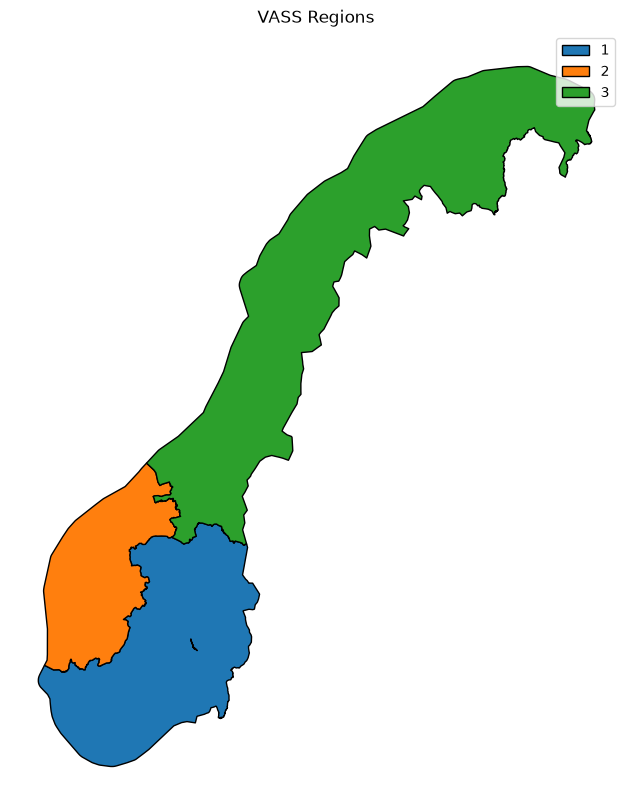

In [144]:
gdf_vass.plot(column="area_id", categorical=True, legend=True,
              edgecolor="black", figsize=(8, 10))

plt.title("VASS Regions")
plt.axis("off")
plt.show()

In [145]:
gdf_no = gdf_regions[["geometry"]].dissolve()
gdf_no["area_id"] = 0

display(gdf_no)

,geometry,area_id
0,"POLYGON ((231754.99 6523881.03, 227516.34 6524...",0


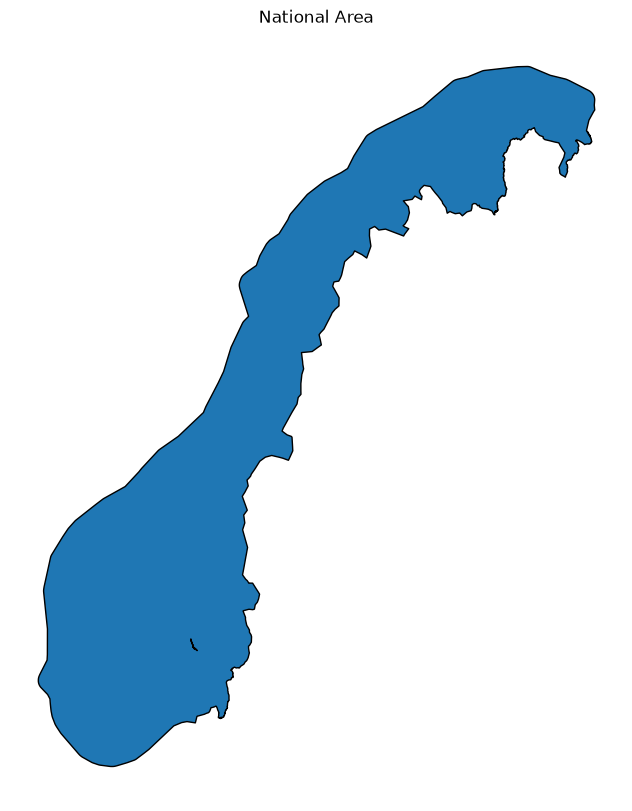

In [146]:
gdf_no.plot(edgecolor="black", figsize=(8, 10))

plt.title("National Area")
plt.axis("off")
plt.show()

In [148]:
gdf_zones["area_id"] = gdf_zones["budomr"].str.extract(r"(\d+)").astype(int)

gdf_el = gdf_zones[["area_id", "geometry"]].copy()

display(gdf_el)

,area_id,geometry
0,1,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,2,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,3,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,4,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,5,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


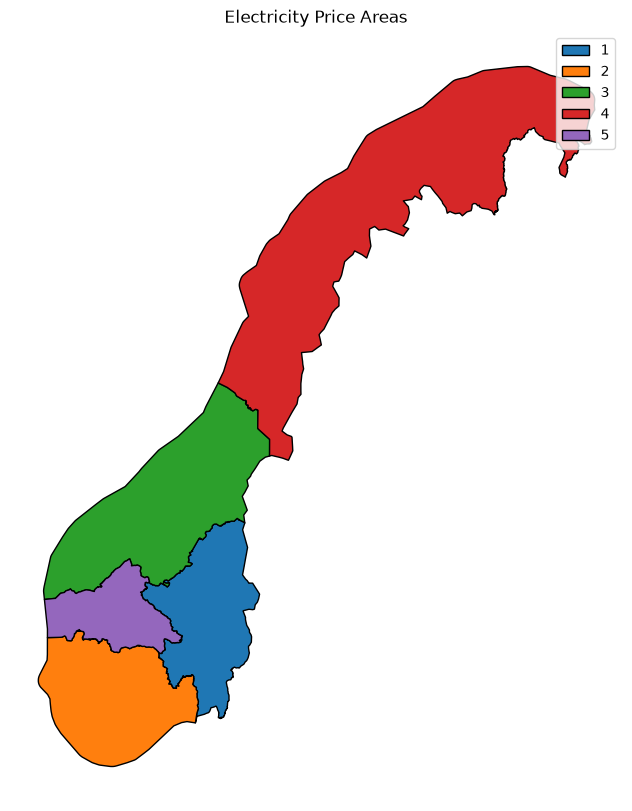

In [149]:
gdf_el.plot(column="area_id", categorical=True, legend=True,
            edgecolor="black", figsize=(8, 10))

plt.title("Electricity Price Areas")
plt.axis("off")
plt.show()

# Convert coordinate systems
We have now looked at and converted the three areas into mappings, and now we need to convert them to the coordinate form EPSG:4326, which displays latitude and longtitude. 

In [151]:
gdf_no = gdf_no.to_crs(epsg=4326)
gdf_el = gdf_el.to_crs(epsg=4326)
gdf_vass = gdf_vass.to_crs(epsg=4326)

In [152]:
gdf_no.to_file("data/geojson/no.geojson", driver="GeoJSON")
gdf_el.to_file("data/geojson/el.geojson", driver="GeoJSON")
gdf_vass.to_file("data/geojson/vass.geojson", driver="GeoJSON")

# Sketch of structure
![Image description](../images/structure_sketch.png)

# AI Usage

ChatGPT was used throughout Task 4 to help with programming, understand different methods, discuss possible solutions and troubleshoot problems.

I provided ChatGPT with the lecture materials and code from the lecturer’s GitHub repository. This helped me follow the methods and implementations used in the lectures as closely as possible.

## Forecasting and data analysis

I used AI to better understand the River framework, particularly online learning, StandardScaler, SGD and recursive forecasting.

We discussed different ways to prepare the data, create lagged variables and include meteorological variables in the model.

AI also helped me implement different model configurations and evaluation methods. I tested the models in the notebook and compared them based on their actual performance.

I used AI to discuss and interpret the correlation analysis and forecasting results, including possible reasons why adding weather variables did not improve the model overall.

## Streamlit implementation

AI was used extensively to move the existing notebook code into Streamlit and restructure the application.

This included:

- Implementing shared selectors with session state.
- Converting existing Matplotlib plots to Plotly.
- Creating the interactive geographical map and area selection.
- Generalising the weather-loading and statistical analysis functions.
- Building the forecasting interface and Plotly animation.
- Adding caching and feedback for time-consuming operations.

I developed most of the code step by step, testing each part before moving on. AI also helped me refactor the code into reusable functions and separate files.

## Troubleshooting

AI was especially useful when I ran into technical problems during development. For example:

- Keeping session state selections between pages.
- Addressing numerical instability in recursive forecasting.
- Handling missing weather observations and reusing previously downloaded data.
- Resolving issues with imports and cached functions.
- Deploying to Streamlit Cloud and removing unnecessary dependencies from `requirements.txt`.
- Investigating why the interactive map reported incomplete weather data despite 100% timestamp coverage.

Some suggestions didn’t work straight away and needed further testing or adjustment. In a few cases, I chose a simpler solution instead of following a more complicated suggestion.

## Documentation

AI helped me structure and summarise the activity log using my own notes, experimental results and earlier project discussions.

## Reflection on AI usage

Compared with earlier parts of the project, I used AI more for application development and code organisation, mainly because of the amount of functionality that needed to be integrated into Streamlit.

The main benefit was being able to discuss different approaches and troubleshoot problems without spending too much time searching through documentation.

The forecasting experiments also showed why suggestions need to be tested rather than assumed to work. For instance, the correlation analysis suggested that weather variables might help, but the model evaluation showed that the simpler model performed better overall.

I used AI both to generate code and to understand it, discuss design decisions and interpret results. I tested and adjusted the suggested implementations throughout the project.

# Log

## Timezone investigation

I reviewed the timestamp formats and time resolutions of the four data sources:

- NVE Magasinstatistikk: weekly reporting dates with no timezone information.
- Norges Bank: daily reporting dates with no timezone information.
- Open-Meteo: weather observations in UTC.
- ENTSO-E: UTC timestamps from the XML API, which MongoDB returns without timezone information.

I chose a weekly resolution for the forecasting model to match the NVE data and keep computation manageable. Temperature and exchange rates can be averaged, while precipitation and electricity transfers can be summed.

I also identified that timezone differences, daylight saving time and the data available at prediction time all need to be considered.

## Initial forecasting

I built a linear regression model with River, StandardScaler and SGD.

For one-week-ahead forecasts, the initial model had an MAE of 0.028, compared with 0.0265 for persistence. Recent reservoir filling levels appear to be highly informative, and River did not improve short-term predictions.

I then tested recursive forecasts over 12 weeks, using each prediction as an input for the next. River achieved an average MAE of 0.1170, compared with 0.1439 for persistence. Persistence did better during some periods when filling levels were stable, but River performed better overall.

## Sliding Window Correlation

I used SWC with different lags to examine correlations between weekly changes in reservoir filling and weather variables.

I found that temperature was strongly correlated during winter and spring, but less so in summer. One possible explanation is that temperature affects snowmelt.

Precipitation showed stronger correlations from late summer through winter, and weaker ones in spring and early summer. Although its overall correlation was initially 0.130, some periods had considerably higher values.

The results suggested that temperature and precipitation may provide complementary information at different times of year.

By extending the lag analysis to 52 weeks, I discovered an annual pattern for temperature. Correlation fell from about 0.65 at lag 0 to -0.57 around lag 25, then rose to 0.59 around lag 47. Precipitation showed a weaker annual pattern.

This led me to test longer weather lags. With sufficiently long lags, the model can forecast 12 weeks ahead without needing estimates of future weather.

## Model optimisation and weather features

I extended the historical weather dataset for NO3 to cover 2014–2024, giving me about 10 years of usable training data after accounting for lag initialisation.

I aggregated daily weather observations into weekly values and joined them with reservoir data by ISO year and week.

I tested several weather lags, rolling weather features and learning rates from 0.001 to 0.1. To account for seasonal differences, I evaluated the models over four separate 12-week periods.

Average one-week-ahead MAE:

- Baseline: 0.02247
- Weather lag 1: 0.04128
- Weather lags 1, 2, 4: 0.03787
- Weather rolling 4: 0.03868

The baseline performed best overall, though weather improved predictions in some periods.

I conducted further tests of recursive forecasting, which produced the following average MAEs:

- River without weather: 0.08152
- Seasonal naive: 0.09301
- River with long weather lags: 0.13273
- River with short weather lags: 0.13995
- Persistence: 0.17432

Although weather was fairly strongly correlated with reservoir changes, I found that adding it did not improve the model overall.

I selected River without weather as the default model. It uses reservoir lags of 1, 2, 4 and 52 weeks, a learning rate of 0.09, 10 years of training history and a 12-week forecast horizon.

I kept weather available as an optional input. When future weather is unknown, the model uses historical averages for the corresponding week of the year.

I concluded that I had tested enough model variations and that further fine-tuning was unlikely to yield much improvement.

## Streamlit structure and navigation

I sketched the application structure before implementation.

I reorganised the pages into Data Overview, Data Analysis and Prediction, alongside the homepage and interactive map.

I added global area and date selectors using session state. Getting selections to persist when switching between pages took some additional work.

I kept local selectors where they were more useful, such as those for electricity transfer connections and model parameters.

## Interactive map

I converted the shapefiles to GeoJSON and reprojected the coordinates to EPSG:4326.

I added map colouring for NO, EL and VASS areas, as well as colouring based on average temperature and total precipitation over the selected period.

I implemented functionality so that clicking an area changes its outline and updates the global area selection.

Weather colouring is currently available only for EL areas, which are the areas with weather sampling coordinates. Regions with incomplete weather data appear grey.

## Weather data management

I combined the hourly and daily weather loading functions into a general function that supports different resolutions and numbers of sampling locations.

I added a separate Weather Data page where users can check coverage and download missing observations.

To reduce waiting time and API use, I limited new downloads to daily resolution and 100 sampling locations. Previously downloaded hourly data from 1,000 locations is still available.

I downloaded daily weather data for all five EL areas from January 2024 onward and updated the default global timeframe.

## Anomaly detection and SWC

I updated the existing SATV/SPC and LOF functions to work with both temperature and precipitation, while keeping temperature as the default.

I added daily and hourly resolutions, with parameter limits adjusted to the number of available observations.

I kept NO3 hourly data from 2024 as the default for anomaly detection, with the option to use global selections.

I moved the existing SWC implementation from the notebook into Streamlit. Users can select the weather variable, lag and window length. I excluded incomplete weeks to avoid misleading precipitation totals.

## Forecasting in Streamlit

I moved the forecasting functions from the notebook into Streamlit.

I added controls for training history, forecast horizon, learning rate, reservoir lags and optional weather variables.

I set the forecast start date to be determined by the global end date. Users can also choose to train on the full global date range.

I added a Plotly animation that displays recursive predictions step by step.

With 10 years of NO3 training data, I found that a learning rate of 0.09 caused numerical instability. Both increasing and decreasing the rate produced more stable results.

As a practical adjustment, I changed the default learning rate to 0.08 and added checks to prevent physically invalid predictions from being displayed.

## Theme and visualisation

I replaced the remaining Matplotlib plots with Plotly, including plots for reservoir data, electricity transfers, STL decomposition, spectrograms and anomaly detection.

I left the underlying statistical methods unchanged.

I applied a consistent dark blue theme throughout the application.

## Bonus task – Waiting time

I chose Waiting time as the bonus task.

I added caching for API requests, MongoDB connections, retrieved datasets, GeoJSON files and statistical analyses, including forecasting.

I ensured that previously downloaded weather data is reused and that only missing periods are fetched. I also made sure that weather downloads are saved in separate batches.

An Open-Meteo request for NO2 became unresponsive. After restarting the application, I was able to reuse the batches that had already downloaded instead of starting over.

I added spinners and weather coverage indicators to give users feedback during longer operations. I also considered cache expiry and limits on the number of cached results.

## Deployment and troubleshooting

I initially encountered deployment issues with the updated application on Streamlit Cloud. The requirements file included the entire local Python environment, including Windows-specific and unrelated packages.

I pared it down to the packages the application actually needs, which resolved the problem.

The interactive map also showed incomplete weather data, even though the Weather Data page reported 100% coverage.

I found that the three most recent observations had NaN values despite having timestamps. This was most likely due to the publication delay for ERA5 data.

I adjusted the map’s weather end date to account for a seven-day publication delay without changing the global reservoir timeframe.

I then successfully tested the application online.